# Shape the data

We measure one tumor with each assay of `iscc`, in the order bulk DNA, single-cell DNA, scRNA-seq and Visium, and change the data each assay produces.
For each assay we choose a technology preset, switch the measurement biases on and off, and fit the assay parameters to a real data set.
We then simulate batches and write the data in the formats that analysis tools read.
The tumor is the one of [Quickstart](01_quickstart.ipynb), and [Shape the tumor](02_shape_the_tumor.ipynb) changes the tumor itself.

In [1]:
%matplotlib inline
import os, shutil, tempfile, urllib.request, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="nopython is set")
warnings.filterwarnings("ignore", message="Variable names are not unique")
warnings.filterwarnings("ignore", message="max_cells=")   # a dissociation is a subsample by design

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import squidpy as sq
from scipy.spatial import cKDTree
from sklearn.metrics import roc_auc_score, silhouette_score

from iscc.tumor import GenotypeTumor
from iscc.sample import Resection
from iscc.data import (bulkDNA, scDNA, scRNA, Visium, estimate_dna, estimate_rna, estimate_visium,
                       morans_i, run_scrna_batches, concat_batches)
from iscc.integrations import to_anndata, biological_types

sc.settings.verbosity = 0

## One tumor, sampled twice

We grow the tutorial tumor to 25,000 cancer cells and cut the resected specimen in two.
One half is dissociated for the sequencing assays, and a thin section of the other half goes on a Visium slide.

In [2]:
tumor = GenotypeTumor(config="tutorial_config.yaml", seed=1)
tumor.grow(n_steps=20_000, target_cancer=25_000, materialize=False)

specimen = Resection(tumor)
half_seq, half_section = specimen.bisect(frac=0.5, axis="y")
cells = specimen.dissociate(half_seq, max_cells=6000, layers=["scdna", "scrna"], seed=0)
section = specimen.slice(half_section, depth_frac=0.2, max_cells=50_000, layers="visium")

cell_type = pd.Series(biological_types(cells["cell_type"]["cell_id"]), index=cells["cell_type"].index)
print(f"tumor: {tumor.get_cancer_size():,} cancer cells of {tumor.get_tumor_size():,}")
print(f"dissociated half: {len(cell_type):,} cells,", cell_type.value_counts().to_dict())
print(f"section: {len(section['cell_exp']):,} cells,",
      pd.Series(biological_types(section["cell_type"]["cell_id"])).value_counts().to_dict())

tumor: 25,018 cancer cells of 111,395
dissociated half: 6,065 cells, {'stromal': 4474, 'cancer': 1215, 'epithelial': 376}
section: 11,181 cells, {'stromal': 7979, 'cancer': 2666, 'epithelial': 536}


Most cells of the tumor are stromal cells of the ductal field.
The dissociation keeps a subsample of about 6,000 cells of its half, and the section keeps a fifth of the depth of each deme.

## Bulk DNA

[`bulkDNA`](https://pedrofale.github.io/iscc/reference/bulkDNA/) pools the dissociated cells into one library.
The coverage of a locus is proportional to its pooled copy number and to a capture efficiency.
A Dirichlet-multinomial spreads the reads over the loci, and its concentration `kappa` sets how even the coverage is.
The breadth (`"wgs"`, `"wes"` or `"panel"`) sets which loci are read, the mean depth and the dominant capture bias.
To compare runs we divide the coverage of each locus by its true pooled copy number and report the coefficient of variation (CV) of this coverage per copy over loci.
We also report the spread of the variant allele fraction (VAF) at the germline heterozygous loci of the tumor.

In [3]:
het_loci = cells["cell_snv"].columns[tumor.germline_sites[tumor.germline_zygosity == "het"]]

def bulk_summary(run):
    od = run.observed_data
    per_copy = od["coverage"] / od["true_cn"]
    return {"loci": len(od), "mean coverage": od["coverage"].mean(),
            "coverage CV": per_copy.std() / per_copy.mean(),
            "VAF sd at germline hets": od.loc[od.index.isin(het_loci), "vaf"].std()}

default = {b: bulkDNA(breadth=b, seed=1).run(cells) for b in ["wgs", "wes", "panel"]}
print(f"tumor purity of the pool: {default['wgs'].purity:.2f}, "
      f"{len(het_loci)} germline heterozygous loci")
pd.DataFrame({b: bulk_summary(r) for b, r in default.items()}).T.round(2)

tumor purity of the pool: 0.20, 28 germline heterozygous loci


,loci,mean coverage,coverage CV,VAF sd at germline hets
wgs,6000.0,30.0,1.77,0.31
wes,1800.0,120.0,0.99,0.03
panel,30.0,1500.0,0.46,NaN


Cancer cells make up 20% of the pool, and this purity is what a copy number or clone caller has to estimate.
With the default `kappa` of 2,000, the WGS coverage per copy has a CV of 1.77, and the VAF at germline heterozygous loci has a standard deviation of 0.31.
Real WGS is far more even, and over 20,000 sites of the GIAB HG002 benchmark genome (Zook et al., 2019) the CV of the coverage is 0.41.
Fitted to these sites, `estimate_dna` gives a `kappa` of about 121,000.
The excess CV of a Dirichlet-multinomial is about the square root of the number of loci over `kappa`, so a concentration fitted on 20,000 sites gives a different spread on the 6,000 loci of the tutorial genome.
`kappa_loci` records the number of loci of the fit, and the assay rescales `kappa` to its own loci.

In [4]:
hg002 = dict(kappa=121_000, kappa_loci=20_000)
bulk = {"WGS 30x": bulkDNA(breadth="wgs", seed=1, **hg002).run(cells),
        "WGS 100x": bulkDNA(breadth="wgs", mu_depth=100, seed=1, **hg002).run(cells),
        "WES": bulkDNA(breadth="wes", seed=1, **hg002).run(cells),
        "panel": bulkDNA(breadth="panel", seed=1, **hg002).run(cells)}
pd.DataFrame({b: bulk_summary(r) for b, r in bulk.items()}).T.round(2)

,loci,mean coverage,coverage CV,VAF sd at germline hets
WGS 30x,6000.0,30.0,0.46,0.11
WGS 100x,6000.0,100.0,0.43,0.06
WES,1800.0,120.0,0.52,0.06
panel,30.0,1500.0,0.56,NaN


With the concentration fitted to HG002, the CV of the WGS coverage falls to 0.46 at 30x and 0.43 at 100x.
The standard deviation of the VAF at germline heterozygous loci falls from 0.11 at 30x to 0.06 at 100x.
WES reads 30% of the loci at 120x and the panel reads 30 loci at 1,500x.
Both add a per-target capture efficiency (`capture_sigma` 0.3 and 0.45), which raises their CV to 0.52 and 0.56.
The panel covers none of the germline heterozygous loci.
We plot the coverage per copy along the genome at both concentrations, and its median against GC content for three strengths of the GC bias (`gc_curve_sigma`).

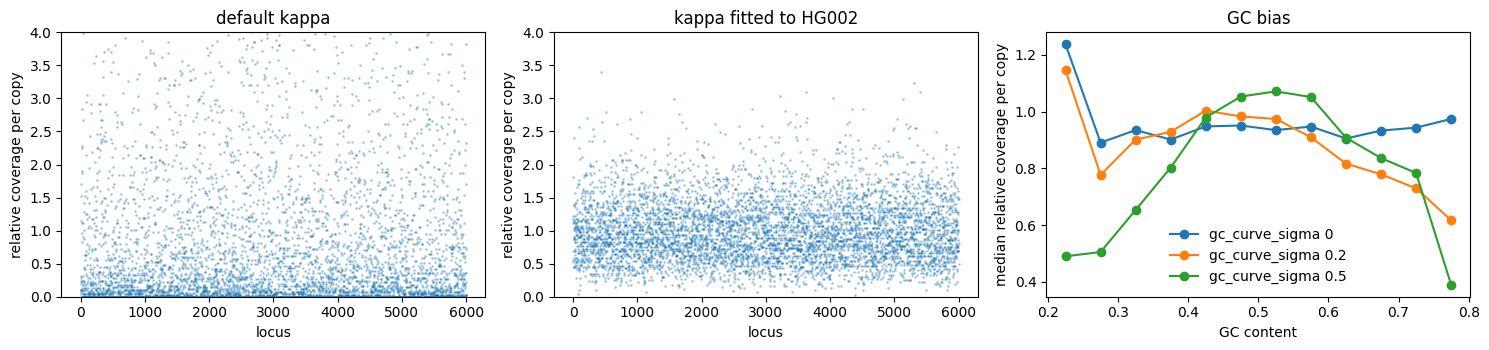

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, run, title in [(axes[0], default["wgs"], "default kappa"), (axes[1], bulk["WGS 30x"], "kappa fitted to HG002")]:
    per_copy = run.observed_data["coverage"] / run.observed_data["true_cn"]
    ax.scatter(np.arange(len(per_copy)), per_copy / per_copy.mean(), s=1, alpha=0.3)
    ax.set(title=title, xlabel="locus", ylabel="relative coverage per copy", ylim=(0, 4))
gc_bins = np.arange(0.2, 0.81, 0.05)
for gc_sigma in [0.0, 0.2, 0.5]:
    od = bulkDNA(breadth="wgs", gc_curve_sigma=gc_sigma, seed=1, **hg002).run(cells).observed_data
    per_copy = od["coverage"] / od["true_cn"]
    curve = (per_copy / per_copy.mean()).groupby(pd.cut(od["gc"], gc_bins), observed=True).median()
    axes[2].plot([b.mid for b in curve.index], curve.values, "o-", label=f"gc_curve_sigma {gc_sigma:g}")
axes[2].set(title="GC bias", xlabel="GC content", ylabel="median relative coverage per copy")
axes[2].legend(frameon=False)
plt.tight_layout()

At the default concentration most loci receive almost no reads and a few receive several times the mean, while the fitted concentration leaves an even band.
The GC bias lowers the coverage of GC-rich loci, and at the strongest setting also that of GC-poor loci.

## Single-cell DNA

[`scDNA`](https://pedrofale.github.io/iscc/reference/scDNA/) draws the coverage of each cell separately, so that each cell has a different amplification profile.
It loses one allele of a heterozygous locus with probability `ado_rate` (allelic dropout) and overdisperses the allele counts by `beta_binom_conc`.
It also merges a fraction `doublet_rate` of the cells with a partner and marks them in `obs["is_doublet"]`.
We measure the same 300 cells with four settings.
The default single-cell setting keeps a `kappa` of 5.
The DLP+ setting takes the values that [`estimate_dna`](https://pedrofale.github.io/iscc/reference/estimate_dna/) fitted to 40 cells of the DLP+ data set OV2295 (Laks et al., 2019), counted in 5,787 bins of 500 kb.
The Tapestri setting takes those fitted to 800 cells of a 584-amplicon Tapestri panel (Mays et al., 2024).
DLP+ data carry no allele counts, so its dropout of 0.05 is a value we set.
The MDA-like setting is our choice rather than a fit, with the depth of DLP+, a tenfold lower `kappa` for the lumpier coverage of multiple displacement amplification, and a dropout of 0.3.

In [6]:
platforms = {
    "default": dict(breadth="wgs"),
    "DLP+": dict(breadth="wgs", mu_depth=830, kappa=2.0e5, kappa_loci=5787, ado_rate=0.05),
    "MDA-like": dict(breadth="wgs", mu_depth=830, kappa=2.0e4, kappa_loci=5787, ado_rate=0.3),
    "Tapestri": dict(breadth="panel", target_genes=0.1, mu_depth=43, kappa=4700, kappa_loci=584,
                     capture_sigma=0.39, ado_rate=0.32, beta_binom_conc=4.5),
}
assayed = np.random.default_rng(0).choice(cell_type.index, size=300, replace=False)
sc_dna = {p: scDNA(seed=2, **kw).run(cells, cell_subset=assayed) for p, kw in platforms.items()}

def balanced_hets(run):
    # cell-locus pairs that are heterozygous at two copies and have at least 10 reads
    return (run.true_alt_fraction.values == 0.5) & (run.true_cn.values == 2) & (run.coverage.values >= 10)

def scdna_summary(run):
    cov, two = run.coverage.values.astype(float), run.true_cn.values == 2
    cv = [cov[i, two[i]].std() / cov[i, two[i]].mean() for i in range(len(cov))
          if two[i].sum() > 20 and cov[i, two[i]].sum() > 0]
    vaf = run.vaf.values[balanced_hets(run)]
    return {"loci": cov.shape[1], "mean coverage": cov.mean(), "loci without reads": (cov == 0).mean(),
            "coverage CV at 2 copies": np.median(cv),
            "hets read as homozygous": np.mean((vaf <= 0.05) | (vaf >= 0.95))}

print("assayed cells:", cell_type[assayed].value_counts().to_dict())
pd.DataFrame({p: scdna_summary(r) for p, r in sc_dna.items()}).T.round(3)

assayed cells: {'stromal': 212, 'cancer': 66, 'epithelial': 22}


,loci,mean coverage,loci without reads,coverage CV at 2 copies,hets read as homozygous
default,6000.0,9.0,0.992,29.055,0.250
DLP+,6000.0,830.0,0.011,0.244,0.055
MDA-like,6000.0,830.0,0.011,0.563,0.304
Tapestri,600.0,43.0,0.011,0.584,0.315


The default setting is not usable at whole-genome breadth, since with a `kappa` of 5 over 6,000 loci 99% of the loci of a cell receive no read.
The DLP+ setting gives a CV of 0.24 at two copies, the MDA-like setting 0.56 and the Tapestri setting 0.58.
The share of heterozygous loci read as homozygous (0.06, 0.30 and 0.32) is close to each dropout rate.
We plot the coverage of one cancer cell, scaled so that its median is two copies, against its true copy number, and the VAF at the heterozygous loci of all assayed cells with and without dropout.

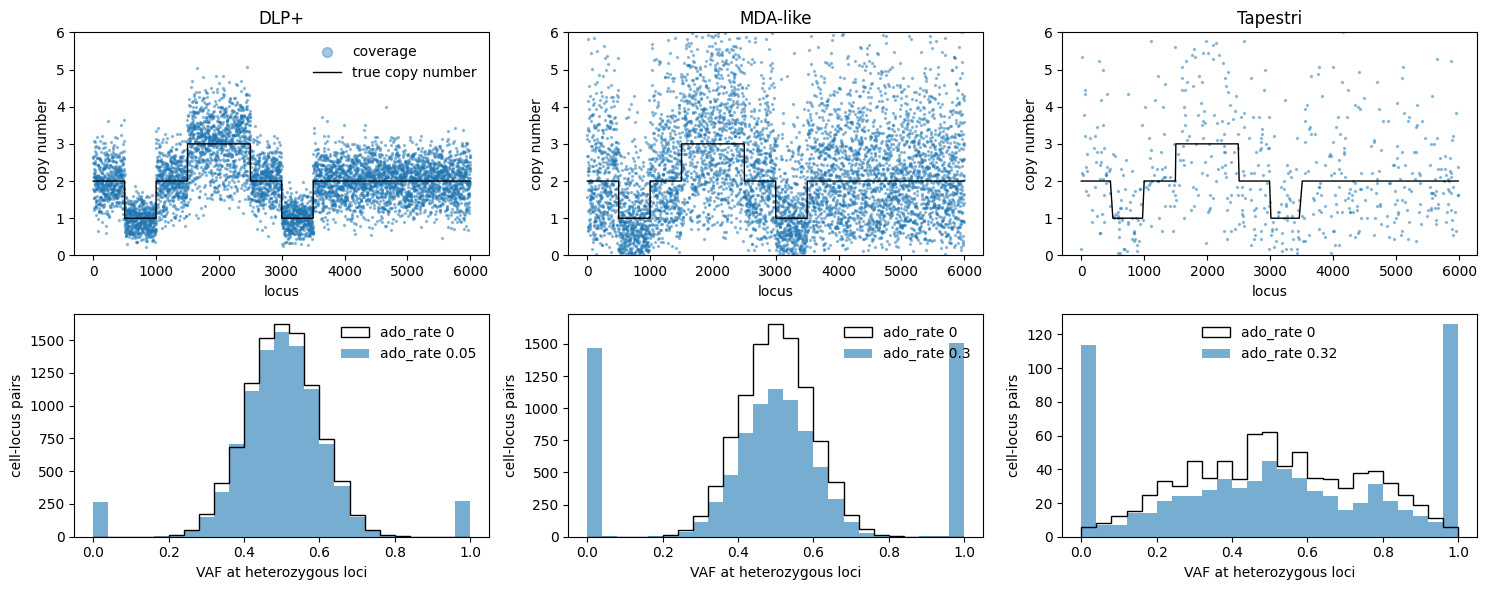

In [7]:
genome = cells["cell_snv"].columns
one_cell = next(c for c in assayed if cell_type[c] == "cancer")
bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for j, p in enumerate(["DLP+", "MDA-like", "Tapestri"]):
    run = sc_dna[p]
    pos = genome.get_indexer(run.genes)
    cov = run.coverage.loc[one_cell]
    axes[0, j].scatter(pos, 2 * cov / cov.median(), s=2, alpha=0.4, label="coverage")
    axes[0, j].plot(pos, run.true_cn.loc[one_cell], color="k", lw=1, label="true copy number")
    axes[0, j].set(title=p, xlabel="locus", ylabel="copy number", ylim=(0, 6))
    no_ado = scDNA(seed=2, **{**platforms[p], "ado_rate": 0.0}).run(cells, cell_subset=assayed)
    axes[1, j].hist(no_ado.vaf.values[balanced_hets(no_ado)], bins=bins, histtype="step", color="k",
                    label="ado_rate 0")
    axes[1, j].hist(run.vaf.values[balanced_hets(run)], bins=bins, alpha=0.6,
                    label=f"ado_rate {platforms[p]['ado_rate']}")
    axes[1, j].set(xlabel="VAF at heterozygous loci", ylabel="cell-locus pairs")
    axes[1, j].legend(frameon=False)
axes[0, 0].legend(frameon=False, markerscale=5)
plt.tight_layout()

The DLP+ coverage is close to the true copy number, the MDA-like coverage is too dispersed to separate neighboring copy number states, and the panel reads a tenth of the loci.
Dropout moves heterozygous loci from around 0.5 to 0 and 1, and the Tapestri allele counts spread far more around 0.5 because of their low `beta_binom_conc`.

On real data, `estimate_dna` takes the coverage and alternative-allele counts of each cell and locus, with the copy number called by a tool such as HMMcopy, and fits the parameters above.
We check it on the simulated Tapestri run, with the true copy number in place of a call and a mask of the heterozygous cell-locus pairs, which on real data come from germline SNPs.

In [8]:
tap = sc_dna["Tapestri"]
fit = estimate_dna(tap.coverage.values, tap.alt_counts.values, tap.true_cn.values,
                   modality="sc", breadth="panel", gc=tap.gc,
                   het_mask=(tap.true_alt_fraction.values > 0.15) & (tap.true_alt_fraction.values < 0.85))
print("fitted:", fit.fitted)
keys = ["mu_depth", "capture_sigma", "ado_rate", "beta_binom_conc"]
table = pd.DataFrame({"set": [tap.hypers.to_dict()[k] for k in keys],
                      "fitted": [fit.hypers.to_dict()[k] for k in keys]}, index=keys)
table.loc["kappa per locus"] = [tap.hypers.kappa / tap.hypers.kappa_loci, fit.hypers.kappa / fit.hypers.kappa_loci]
table.round(3)

fitted: ['mu_depth', 'gc_curve_sigma', 'kappa', 'capture_sigma', 'ado_rate', 'beta_binom_conc']


,set,fitted
mu_depth,43.000,43.000
capture_sigma,0.390,0.373
ado_rate,0.320,0.297
beta_binom_conc,4.500,4.840
kappa per locus,8.048,8.153


The fitted values are within 8% of the settings, and `fit.dna_kwargs()` passes them to `scDNA` or `bulkDNA`.

## scRNA-seq

[`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/) draws the UMI counts of each cell from the true expression of the cell, with a log-normal library size (`mu_lib`, `sigma_lib`) and a negative binomial (`dispersion`), and adds ambient RNA, doublets and an optional logistic dropout.
The `protocol` presets set all of them.
The 10x preset is a droplet protocol with ambient RNA and doublets, and the Smart-seq3 preset sorts one cell per well onto 384-well plates, deeper and with less ambient RNA.

In [9]:
def rna_summary(run):
    X = run.observed_counts.values
    return {"median UMIs": np.median(X.sum(1)), "median genes": np.median((X > 0).sum(1)),
            "zeros": (X == 0).mean(), "doublets": run.obs["is_doublet"].mean(),
            "plates": run.obs["plate"].nunique() if "plate" in run.obs else 0}

protocols = {p: scRNA(protocol=p, n_cells=2000, seed=1).run(cells) for p in ["10x", "smartseq3"]}
pd.DataFrame({p: rna_summary(r) for p, r in protocols.items()}).T.round(3)

,median UMIs,median genes,zeros,doublets,plates
10x,2445.0,649.0,0.889,0.05,0.0
smartseq3,6912.0,1529.0,0.745,0.01,6.0


With the 10x preset the median is 2,445 UMIs per cell, below the `mu_lib` of 4,000, because the dropout of the preset (`dropout_mid` 1.5, set by hand) deletes counts after the library size is drawn.
Smart-seq3 has no dropout and a `mu_lib` of 8,000, and its 2,000 cells fill six plates.

### Dropout and depth

`dropout_mid` is the mean count at which a gene is dropped with probability one half, and 0 switches dropout off.
We plot the fraction of cells with zero UMIs against the mean UMIs of each gene for three midpoints, and the genes detected per cell at three depths (`mu_lib`).

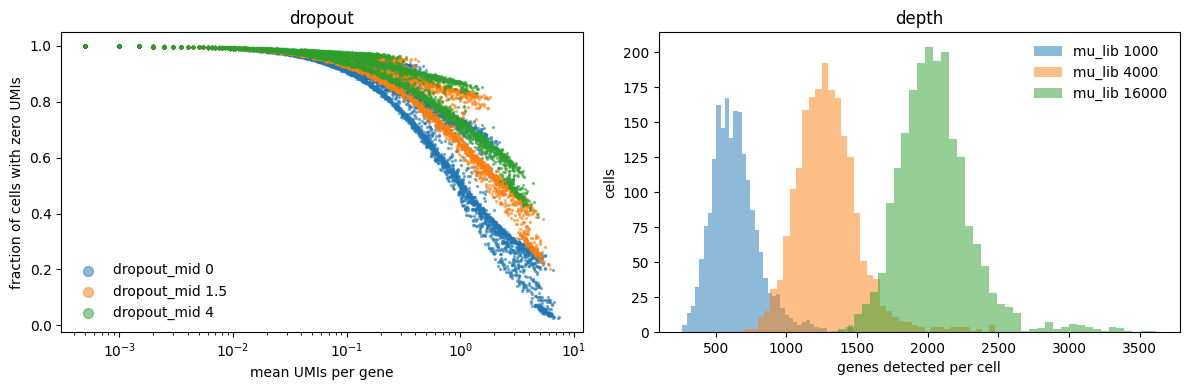

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for mid in [0.0, 1.5, 4.0]:
    X = scRNA(n_cells=2000, dropout_mid=mid, seed=1).run(cells).observed_counts.values
    axes[0].scatter(X.mean(0), (X == 0).mean(0), s=2, alpha=0.5, label=f"dropout_mid {mid:g}")
axes[0].set(xscale="log", xlabel="mean UMIs per gene", ylabel="fraction of cells with zero UMIs",
            title="dropout")
for depth in [1000, 4000, 16000]:
    X = scRNA(n_cells=2000, mu_lib=depth, dropout_mid=0, seed=1).run(cells).observed_counts.values
    axes[1].hist((X > 0).sum(1), bins=40, alpha=0.5, label=f"mu_lib {depth}")
axes[1].set(xlabel="genes detected per cell", ylabel="cells", title="depth")
for ax in axes:
    ax.legend(frameon=False, markerscale=5)
plt.tight_layout()

Dropout raises the zero fraction of genes with more than about 0.1 UMIs per cell.
With the depth, the genes detected per cell rise from about 600 at 1,000 UMIs to about 2,000 at 16,000 UMIs.
`estimate_rna` leaves dropout off on real data (see the fit to PBMC3k below), so we switch it off (`dropout_mid=0`) in the runs that follow.

### Dissociation

[`Resection.dissociate`](https://pedrofale.github.io/iscc/reference/Resection/) applies the biology of the dissociation itself.
Cells of each type are recovered with a probability set by `recovery_probs` (by default 0.9 for cancer, 0.8 for epithelial and 0.6 for stromal cells).
The expression of a random 5% of the genes of every recovered cell is then multiplied by `1 + stress_strength`.
We dissociate the same half again with both and measure the two dissociations with the same 10x run.

In [11]:
stressed = specimen.dissociate(half_seq, max_cells=6000, layers=["scdna", "scrna"],
                               recovery_probs="default", stress_strength=2.0, seed=0)
stress_genes = specimen.dissociation_meta["stress_genes"]
print(f"recovered {len(stressed['cell_exp']):,} of {len(cells['cell_exp']):,} cells, "
      f"{len(stress_genes)} stress genes")

rows = {}
for name, sample in [("plain dissociation", cells), ("recovery and stress", stressed)]:
    run = scRNA(n_cells=2000, dropout_mid=0, seed=1).run(sample)
    counts = run.observed_counts
    rows[name] = pd.Series(biological_types(run.obs["clone"])).value_counts(normalize=True)
    rows[name]["stress-gene share of UMIs"] = (counts[stress_genes].sum(1) / counts.sum(1)).median()
pd.DataFrame(rows).T.round(3)

recovered 4,121 of 6,065 cells, 300 stress genes


,stromal,cancer,epithelial,stress-gene share of UMIs
plain dissociation,0.728,0.214,0.058,0.042
recovery and stress,0.650,0.278,0.072,0.119


The recovery kept 4,121 of the 6,065 cells.
Among the measured cells, the share of cancer cells rose from 0.21 to 0.28 and the share of stromal cells fell from 0.73 to 0.65.
The 300 stress genes, multiplied by three, account for 11.9% of the UMIs of a cell instead of 4.2%.

### Ambient RNA and doublets

Ambient RNA (`ambient_frac`) adds to every cell Poisson counts drawn from the pooled expression of its batch.
To see it, we take the 50 genes most specific to cancer cells in the true expression and measure their share of the UMIs of stromal cells, with dropout off and with the dropout of the 10x preset.

In [12]:
expression = cells["cell_exp"]
cancer_markers = (expression[cell_type == "cancer"].mean()
                  / (expression[cell_type == "stromal"].mean() + 1e-6)).nlargest(50).index

def marker_share_in_stroma(run):
    share = run.observed_counts[cancer_markers].sum(1) / run.observed_counts.sum(1)
    return share[biological_types(run.obs["clone"]) == "stromal"].mean()

rows = {}
for ambient in [0.0, 0.05, 0.2]:
    rows[ambient] = {
        "dropout off": marker_share_in_stroma(scRNA(n_cells=2000, ambient_frac=ambient, dropout_mid=0, seed=1).run(cells)),
        "dropout of the 10x preset": marker_share_in_stroma(scRNA(n_cells=2000, ambient_frac=ambient, seed=1).run(cells))}
pd.DataFrame(rows).T.rename_axis("ambient_frac").round(4)

,dropout off,dropout of the 10x preset
ambient_frac,,
0.00,0.0003,0.0006
0.05,0.0020,0.0005
0.20,0.0061,0.0003


With dropout off, the share of cancer-marker UMIs in stromal cells rises from 0.03% without ambient RNA to 0.20% at the default `ambient_frac` of 0.05 and to 0.61% at 0.2.
With the dropout of the 10x preset it does not rise with the ambient fraction (0.06%, 0.05% and 0.03%).
The dropout probability of a gene is set by the expected expression of the cell, so the dropout deletes almost every ambient count of a gene that the cell does not express.
Data for a benchmark of ambient RNA removal should therefore keep dropout off.

Doublets (`doublet_rate`) merge the counts of two barcodes.
We run Scrublet (`sc.pp.scrublet`), the doublet detector of scanpy, at two doublet rates.

In [13]:
rows = {}
for rate in [0.0, 0.15]:
    adata = scRNA(n_cells=2000, doublet_rate=rate, dropout_mid=0, seed=1).run(cells).to_anndata()
    sc.pp.scrublet(adata, random_state=0)
    doublet = adata.obs["is_doublet"].values
    rows[rate] = {"doublets": doublet.mean(), "called by Scrublet": adata.obs["predicted_doublet"].mean()}
    if doublet.any():
        rows[rate]["UMIs, doublets / singlets"] = (adata.obs["n_counts"][doublet].median()
                                                    / adata.obs["n_counts"][~doublet].median())
        rows[rate]["Scrublet AUROC"] = roc_auc_score(doublet, adata.obs["doublet_score"])
pd.DataFrame(rows).T.rename_axis("doublet_rate").round(3)

,doublets,called by Scrublet,"UMIs, doublets / singlets",Scrublet AUROC
doublet_rate,,,,
0.00,0.00,0.000,NaN,NaN
0.15,0.15,0.002,2.089,0.888


Doublets have about twice the UMIs of single cells (2.09 times at the median).
Scrublet ranks them well (AUROC 0.89), but its automatic threshold flags only 0.2% of the barcodes as doublets, against the 15% simulated.

### Fitting the assay to PBMC3k

[`estimate_rna`](https://pedrofale.github.io/iscc/reference/estimate_rna/) fits the library size and the dispersion of a real count matrix.
We fit it to PBMC3k, a data set of 2,700 blood cells from 10x Genomics, which `scanpy.datasets.pbmc3k()` downloads and which the paper also uses.
Counts alone cannot identify ambient RNA, doublets or a plate layout, so `est.carried` lists the values taken from the preset.
`estimate_rna` does not fit dropout unless asked (`fit_dropout=True`), because UMI counts carry no zeros beyond those of the negative binomial (Svensson, 2020).

In [14]:
pbmc = sc.datasets.pbmc3k()
est = estimate_rna(pbmc, protocol="10x")
print(f"PBMC3k: {est.n_cells:,} cells, {est.n_genes:,} genes")
print("fitted:", est.fitted)
print("carried from the 10x preset:", est.carried)
pd.Series(est.scrna_kwargs())

PBMC3k: 2,700 cells, 32,738 genes
fitted: ['mu_lib', 'sigma_lib', 'dispersion']
carried from the 10x preset: ['ambient_frac', 'doublet_rate', 'kappa', 'well_sigma', 'n_wells', 'n_plates', 'plate_sigma', 'dropout_shape', 'sigma_batch', 'depth_batch_sigma']


protocol                    10x
sigma_batch                 0.1
mu_lib               2366.90037
sigma_lib              0.431431
dispersion             0.608158
ambient_frac               0.05
doublet_rate               0.05
dropout_mid                 0.0
dropout_shape               1.0
well_sigma                  0.0
n_wells                       0
n_plates                      0
plate_sigma                 0.0
depth_batch_sigma          0.05
dtype: object

PBMC3k: median 2,197 UMIs per cell, CV 0.46
simulated with the fit: median 2,232 UMIs per cell, CV 0.48


dropout midpoint fitted on request: 0.94


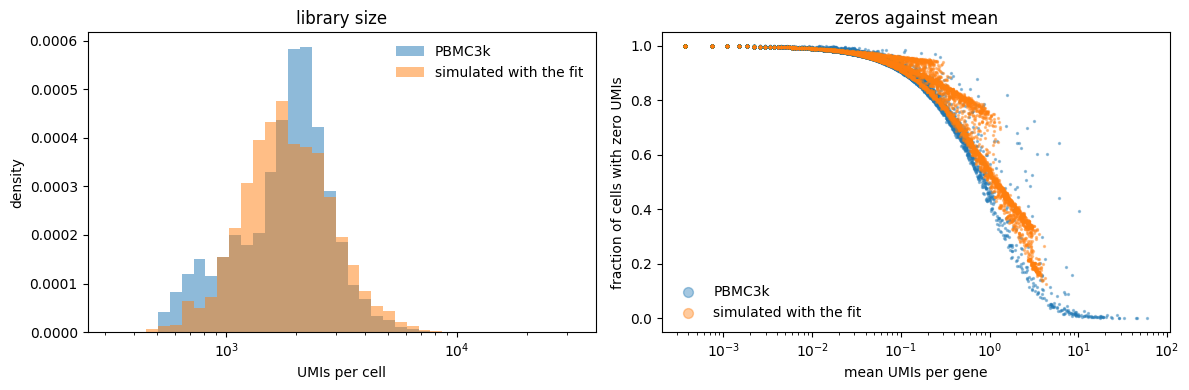

In [15]:
fitted_rna = scRNA(n_cells=est.n_cells, seed=1, **est.scrna_kwargs()).run(cells)
real_X = pbmc.X.toarray()
sim_X = fitted_rna.observed_counts.values

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for X, label in [(real_X, "PBMC3k"), (sim_X, "simulated with the fit")]:
    lib = X.sum(1)
    print(f"{label}: median {np.median(lib):,.0f} UMIs per cell, CV {lib.std() / lib.mean():.2f}")
    axes[0].hist(lib, bins=np.logspace(2.5, 4.5, 40), alpha=0.5, density=True, label=label)
    axes[1].scatter(X.mean(0), (X == 0).mean(0), s=2, alpha=0.4, label=label)
axes[0].set(xscale="log", xlabel="UMIs per cell", ylabel="density", title="library size")
axes[1].set(xscale="log", xlabel="mean UMIs per gene", ylabel="fraction of cells with zero UMIs",
            title="zeros against mean")
for ax in axes:
    ax.legend(frameon=False, markerscale=5)
plt.tight_layout()
print("dropout midpoint fitted on request:", round(estimate_rna(pbmc, fit_dropout=True).hypers.dropout_mid, 2))

The fitted mean library size is 2,367 UMIs per cell, with a log-normal sd of 0.43 and a dispersion of 0.61.
The simulated library sizes match those of PBMC3k (median 2,232 against 2,197 UMIs, CV 0.48 against 0.46).
Genes with fewer than about 0.1 UMIs per cell have the zero fraction of PBMC3k, while more expressed genes have more zeros in the simulation.
The fitted dispersion may include the variation between the cell types of PBMC3k, which the simulation then adds a second time through the cell types of the tumor.
Asked to, `estimate_rna` fits a dropout midpoint of 0.94 UMIs, but it fits this curve to all zeros, including those the negative binomial already draws, so simulating with it would count those zeros twice.

## Visium

[`Visium`](https://pedrofale.github.io/iscc/reference/Visium/) lays the fixed 10x Visium v1 slide of 4,992 spots over the section and pools the cells within the radius of each spot.
It draws the UMIs of each spot with a log-normal depth (`mu_counts`, `sigma_counts`) scaled by a smooth capture field over the slide (`field_sigma`, `field_lengthscale`).
With `section_frac=1.0` the section is placed as it was cut, centered on the slide.

4,992 spots, 1,368 over tissue, median 6 cells per tissue spot


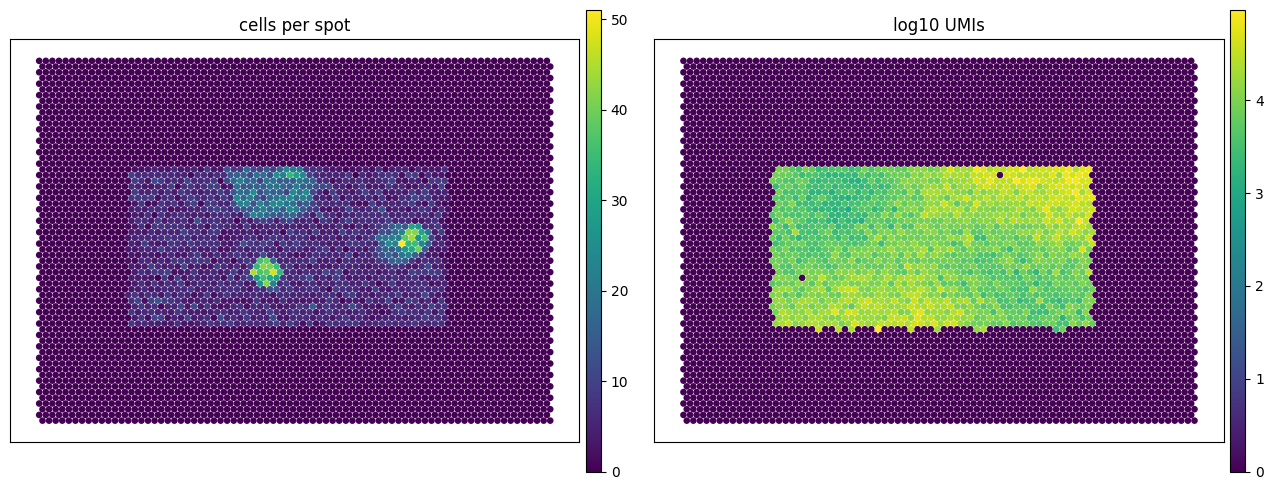

In [16]:
def visium_summary(adata):
    tissue = adata.obs["in_tissue"].values == 1
    umis = np.asarray(adata.X.sum(1)).ravel()
    return {"spots in tissue": tissue.sum(), "median UMIs per tissue spot": np.median(umis[tissue]),
            "mean log10 UMIs per tissue spot": np.log10(umis[tissue]).mean(),
            "Moran's I of the depth": morans_i(umis[tissue], adata.obsm["spatial"][tissue]),
            "share of UMIs outside the tissue": umis[~tissue].sum() / umis.sum()}

visium = Visium(section_frac=1.0, seed=1).run(section)
spots = visium.to_anndata()
tissue = spots.obs["in_tissue"] == 1
print(f"{spots.n_obs:,} spots, {tissue.sum():,} over tissue, "
      f"median {spots.obs['n_cells'][tissue].median():.0f} cells per tissue spot")
spots.obs["log10 UMIs"] = np.log10(1 + spots.obs["total_counts"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sq.pl.spatial_scatter(spots, color="n_cells", img=False, ax=axes[0], title="cells per spot")
sq.pl.spatial_scatter(spots, color="log10 UMIs", img=False, ax=axes[1], title="log10 UMIs")
for ax in axes:
    ax.set(xlabel="", ylabel="")
plt.tight_layout()

The section covers 1,368 of the 4,992 spots, with a median of 6 cells per tissue spot and several times more over the dense glands.
The depth varies smoothly across the section with the capture field, independently of the tissue.

We switch off the capture field, quarter the depth, and switch on spot swapping, the bleeding of counts from their spot to other spots of the slide as SpotClean models it (Ni et al., 2022), which [`bleed`](https://pedrofale.github.io/iscc/reference/visium_bleed/) implements.
Spot swapping takes a bleeding rate (`bleed_rate`) and the share of the bled counts spread over the whole slide (`bleed_distal`).
The rest spreads through a kernel of sd `bleed_sigma`, and we set all three close to the values fitted to a real section below.
For each run we report the depth of the tissue spots, its spatial autocorrelation (Moran's I, `morans_i`) and the share of the UMIs counted outside the tissue.

In [17]:
settings = {"default": {},
            "flat capture field": dict(field_sigma=0.0),
            "a quarter of the depth": dict(mu_counts=5000),
            "spot swapping": dict(bleed_rate=0.3, bleed_distal=0.3, bleed_sigma=6.5)}
slides = {name: Visium(section_frac=1.0, seed=1, **kw).run(section).to_anndata() for name, kw in settings.items()}
pd.DataFrame({name: visium_summary(a) for name, a in slides.items()}).T.round(3)

,spots in tissue,median UMIs per tissue spot,mean log10 UMIs per tissue spot,Moran's I of the depth,share of UMIs outside the tissue
default,1368.0,9362.5,3.989,0.581,0.000
flat capture field,1368.0,20866.0,4.320,-0.011,0.000
a quarter of the depth,1368.0,2343.0,3.386,0.581,0.000
spot swapping,1368.0,8959.0,3.975,0.650,0.107


Without the capture field the depth has no spatial autocorrelation (Moran's I of -0.01 against 0.58), and the median depth of a tissue spot is 20,866 UMIs instead of 9,363, close to the `mu_counts` of 20,000.
With the field on, the median is lower for two reasons.
The field is log-normal, so its median is below its mean, and it has a mean of 1 over the whole slide but a lower mean over the tissue spots of this section (see the fit below).
A quarter of `mu_counts` gives a quarter of the depth.
With spot swapping, 11% of the UMIs are counted outside the tissue, where the other runs count none.

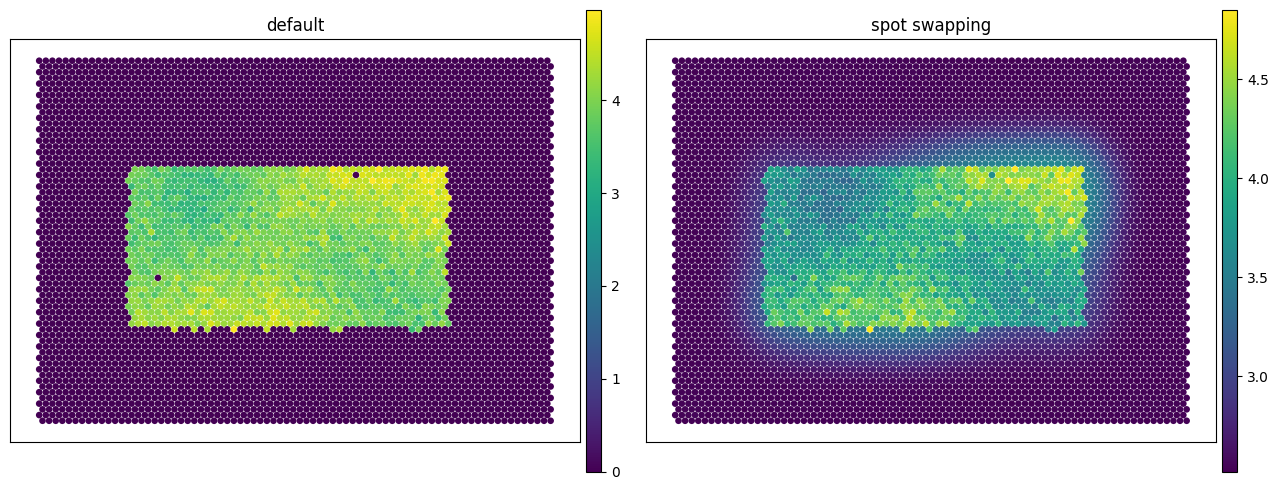

In [18]:
for adata in slides.values():
    adata.obs["log10 UMIs"] = np.log10(1 + adata.obs["total_counts"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["default", "spot swapping"]):
    sq.pl.spatial_scatter(slides[name], color="log10 UMIs", img=False, ax=ax, title=name)
    ax.set(xlabel="", ylabel="")
plt.tight_layout()

With spot swapping, counts spread into a halo around the tissue, and the distal share adds a floor of counts over the whole slide.

### Fitting the assay to a real section

[`estimate_visium`](https://pedrofale.github.io/iscc/reference/estimate_visium/) fits the depth, the capture field and the count overdispersion of a real section from its tissue spots.
Given every spot of the slide with the `in_tissue` flag of Space Ranger, it also fits the spot swapping from the spots outside the tissue.
We fit it to the breast cancer section V1_Breast_Cancer_Block_A_Section_1 of 10x Genomics.
`scanpy.datasets.visium_sge` downloads its images and spot positions, and we download the raw matrix with every spot from the 10x Genomics website.
The coordinates of a real slide are in pixels, so we rescale them to the unit of `iscc`, in which neighboring spots are 2 apart, before fitting the length scale of the field.

In [19]:
sample = "V1_Breast_Cancer_Block_A_Section_1"
sc.datasets.visium_sge(sample)
folder = sc.settings.datasetdir / sample
raw_h5 = folder / "raw_feature_bc_matrix.h5"
if not raw_h5.exists():
    url = f"https://cf.10xgenomics.com/samples/spatial-exp/1.1.0/{sample}/{sample}_raw_feature_bc_matrix.h5"
    request = urllib.request.Request(url, headers={"User-Agent": "scanpy-user"})
    with urllib.request.urlopen(request) as response, open(raw_h5, "wb") as f:
        shutil.copyfileobj(response, f)
real = sc.read_visium(folder, count_file="raw_feature_bc_matrix.h5")
real.var_names_make_unique()
sc.pp.filter_genes(real, min_counts=1)

xy = real.obsm["spatial"].astype(float)
pitch = np.median(cKDTree(xy).query(xy, k=2)[0][:, 1])
est_visium = estimate_visium(real, coords=xy / pitch * 2.0)
print(f"{real.n_obs:,} spots, {int(real.obs['in_tissue'].sum()):,} in tissue, {real.n_vars:,} detected genes")
print("fitted:", est_visium.fitted)
pd.Series(est_visium.visium_kwargs())

4,992 spots, 3,798 in tissue, 25,062 detected genes
fitted: ['mu_counts', 'sigma_counts', 'field_sigma', 'field_lengthscale', 'kappa', 'bleed_rate', 'bleed_distal', 'bleed_sigma', 'edge_sigma']


spot_pitch                    2.0
spot_radius                   1.0
mu_counts            21814.716166
sigma_counts              0.45523
field_lengthscale        18.04158
field_sigma              0.697465
edge_sigma               0.286949
edge_reference             tissue
diffusion_sigma               0.0
bleed_rate               0.309789
bleed_distal             0.302934
bleed_sigma                   6.5
sigma_batch                   0.1
ambient_frac                  0.0
kappa                89211.094789
nb_dispersion                 0.3
dtype: object

The fitted bleeding rate is 0.31, of which 30% goes to the whole slide, and the fitted kernel sd is 6.5, or 3.25 spot pitches.
With the bleed fitted, `estimate_visium` sets the ambient RNA within spots to 0 (`ambient_frac`) and measures the loss of depth at the edge from the tissue (`edge_reference="tissue"`).
The count overdispersion `kappa` (89,211) is fitted over the 25,062 genes detected in the real section, and we keep it as fitted.

In [20]:
fitted_visium = Visium(section_frac=1.0, seed=1, **est_visium.visium_kwargs()).run(section)
fitted_spots = fitted_visium.to_anndata()
on_tissue = fitted_spots.obs["in_tissue"] == 1
print(f"mean capture field over the tissue spots: {fitted_spots.obs['capture_field'][on_tissue].mean():.2f}")
pd.DataFrame({"real section": visium_summary(real),
              "simulated with the fit": visium_summary(fitted_spots)}).T.round(3)

mean capture field over the tissue spots: 0.75


,spots in tissue,median UMIs per tissue spot,mean log10 UMIs per tissue spot,Moran's I of the depth,share of UMIs outside the tissue
real section,3798.0,20761.5,4.221,0.742,0.065
simulated with the fit,1368.0,10623.0,4.048,0.661,0.109


The simulated depth has part of the spatial autocorrelation of the real one (Moran's I of 0.66 against 0.74).
Its tissue spots are shallower than those of the real section (median 10,623 against 20,762 UMIs, mean log10 depth 4.05 against 4.22).
One reason is that `estimate_visium` takes `mu_counts` as the mean depth of the tissue spots, while the assay normalizes the capture field to a mean of 1 over the whole slide.
Over the tissue spots of this section the field has a mean of 0.75.
The share of the UMIs counted outside the tissue is higher in the simulation (0.109 against 0.065).
The distal part of the bleed spreads evenly over the slide, and 73% of the simulated slide is outside the tissue against 24% of the real one.

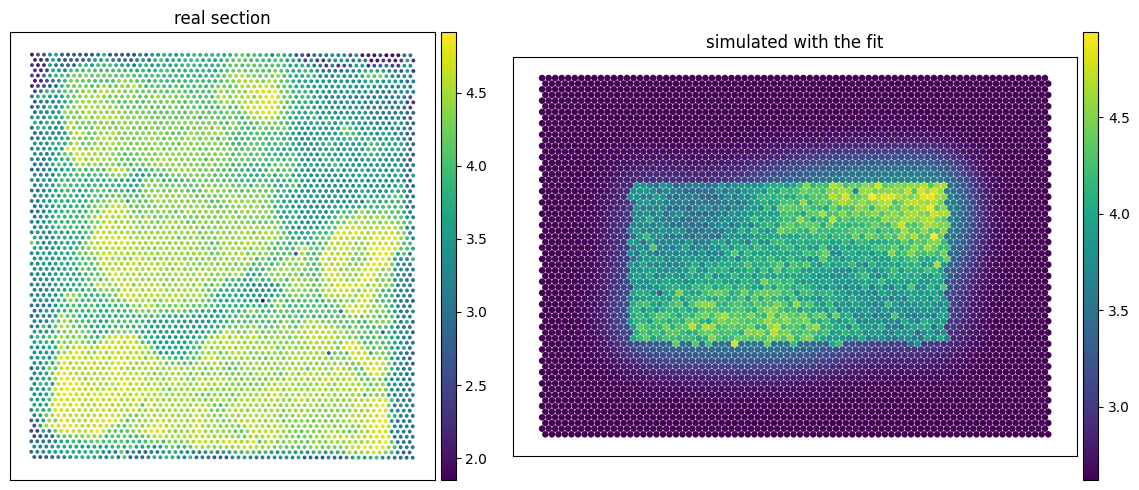

In [21]:
for adata in (real, fitted_spots):
    adata.obs["log10 UMIs"] = np.log10(1 + np.asarray(adata.X.sum(1)).ravel())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sq.pl.spatial_scatter(real, color="log10 UMIs", img=False, ax=axes[0], title="real section")
sq.pl.spatial_scatter(fitted_spots, color="log10 UMIs", img=False, ax=axes[1], title="simulated with the fit")
for ax in axes:
    ax.set(xlabel="", ylabel="")
plt.tight_layout()

The depth of the real section varies in patches that may follow its histology, while the simulated depth follows the capture field, which is independent of the tissue.

## Batches

`run_scrna_batches` measures cells in several batches of one protocol.
Each batch draws its own per-gene factor, the generic batch effect of Splatter with a log-normal sd `sigma_batch`, and its own depth offset (`depth_batch_sigma`), and `batch_kwargs` gives each batch its own parameters.
We split 2,400 cells over three batches, give the second a lower depth and the third more ambient RNA, and merge them with `concat_batches`.
We compare `sigma_batch` 0 and 0.3 by the silhouette of the batch and cell-type labels in PCA space after the standard scanpy normalization.

,silhouette of batch,silhouette of cell type,fitted sigma_batch
sigma_batch,,,
0.0,0.014,0.772,0.034
0.3,0.163,0.711,0.270


fitted depth per batch: {'batch0': 4580, 'batch1': 1578, 'batch2': 4787}


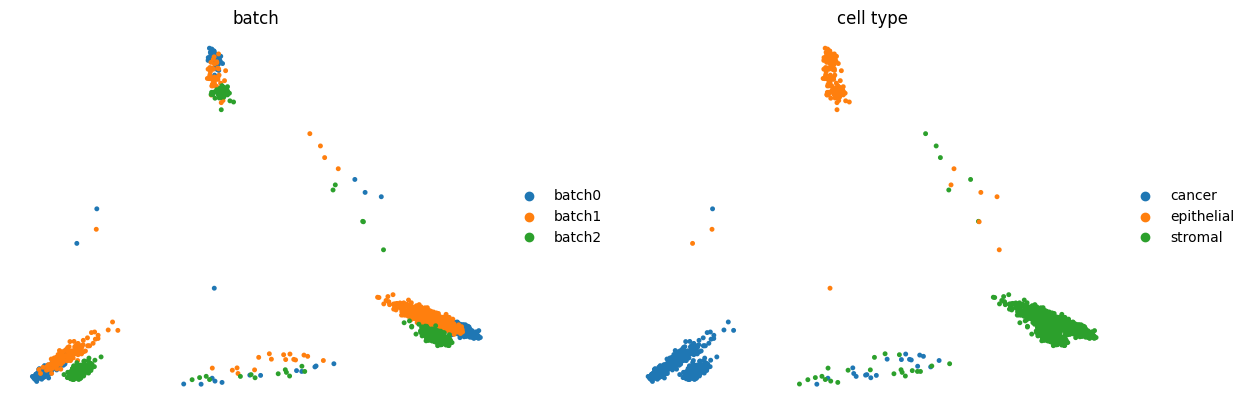

In [22]:
def merged_batches(sigma_batch):
    batches = run_scrna_batches(cells, n_batches=3, design="split", n_cells=800, protocol="10x",
                                sigma_batch=sigma_batch, dropout_mid=0,
                                batch_kwargs=[{}, {"mu_lib": 1500}, {"ambient_frac": 0.2}])
    merged = concat_batches(batches)
    merged.obs["cell type"] = biological_types(merged.obs["clone"])
    batch_fit = estimate_rna(merged, batch_key="batch")
    sc.pp.normalize_total(merged)
    sc.pp.log1p(merged)
    sc.pp.pca(merged, n_comps=20)
    return merged, batch_fit

rows = {}
for sigma_batch in [0.0, 0.3]:
    merged, batch_fit = merged_batches(sigma_batch)
    rows[sigma_batch] = {"silhouette of batch": silhouette_score(merged.obsm["X_pca"], merged.obs["batch"]),
                         "silhouette of cell type": silhouette_score(merged.obsm["X_pca"], merged.obs["cell type"]),
                         "fitted sigma_batch": batch_fit.hypers.sigma_batch}
display(pd.DataFrame(rows).T.rename_axis("sigma_batch").round(3))
print("fitted depth per batch:", {b: round(v["mu_lib"]) for b, v in batch_fit.per_batch.items()})
sc.pl.pca(merged, color=["batch", "cell type"], frameon=False)

With `sigma_batch` 0.3 the batches separate within each cell type (silhouette of the batch labels 0.16 against 0.01), while the cell types stay apart (0.71 against 0.77).
`estimate_rna(adata, batch_key="batch")` fits the batch parameters back from the merged counts, with a `sigma_batch` of 0.27 for 0.3 and of 0.03 for 0.
The depth it fits for the second batch (`per_batch`) is the lowest, as we set it.
On real data with several batches, we pass the fitted parameters of each real batch to `batch_kwargs`, so that each simulated batch has the parameters of a real one.
`run_dna_batches` builds batches of the DNA assays in the same way, and `estimate_visium` fits `sigma_batch` from several sections (`section_labels`).

## Data for analysis tools

Every assay returns an AnnData with `to_anndata()` and writes its tables and an h5ad file with `write(path)`, and [`iscc.integrations.to_anndata`](https://pedrofale.github.io/iscc/reference/to_anndata/) packs the true per-cell tables of a sample.
We write the runs of this tutorial to a temporary folder.

In [23]:
out = tempfile.mkdtemp()
bulk["WGS 30x"].write(os.path.join(out, "bulk_wgs"))
sc_dna["DLP+"].write(os.path.join(out, "scdna_dlp"))
fitted_rna.write(os.path.join(out, "scrna_10x"))
fitted_visium.write(os.path.join(out, "visium"))
to_anndata(cells).write_h5ad(os.path.join(out, "truth_dissociated.h5ad"))
for root, _, files in sorted(os.walk(out)):
    for f in sorted(files):
        print(os.path.relpath(os.path.join(root, f), out))

truth_dissociated.h5ad
bulk_wgs/counts.csv
bulk_wgs/dnabatch1.h5ad
scdna_dlp/alt_counts.csv
scdna_dlp/coverage.csv
scdna_dlp/dnabatch2.h5ad
scrna_10x/batch1.h5ad
scrna_10x/umis.csv
visium/spot_cell_counts.csv
visium/spot_cell_ids.csv
visium/spot_crd.csv
visium/spot_umi.csv
visium/visium1.h5ad


The tool tutorials start from these outputs.

- [HMMcopy](tool_hmmcopy.ipynb) calls copy number from the scDNA coverage.
- [PyClone-VI](tool_pyclonevi.ipynb) infers clones from the bulk read counts.
- [clonealign](tool_clonealign.ipynb) assigns scRNA cells to the clones of the scDNA copy number.
- [Copy number from scRNA](tool_scrna_cnv.ipynb) infers copy number and malignancy from the scRNA counts.
- [RCTD](tool_rctd.ipynb) deconvolves the Visium spots into cell types.
- [Harmony and scVI](tool_integration.ipynb) integrate the scRNA batches of a [cohort](04_cohort.ipynb).
- [MHN](tool_mhn.ipynb) learns progression models from the DNA of a cohort.

Tools that need real gene names and chromosome positions read human-gene versions of these files.
For them we grow the tumor on an arm genome ([`arm_genome`](https://pedrofale.github.io/iscc/reference/arm_genome/)), measure it through the [human genome layer](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/), and write Cell Ranger and Space Ranger output with [`write_scrna`](https://pedrofale.github.io/iscc/reference/write_scrna/) and [`write_visium`](https://pedrofale.github.io/iscc/reference/write_visium/).